## Advanced Forecasting with XGBoost

In `PreliminaryForecasts.ipynb` we forecast each reactor's average quarterly power with four methods:

1. **Seasonal naive**: repeat the most recent refueling cycle.
2. **Seasonal rolling average**: average the same point over the last few cycles.
3. **Holt-Winters (Exponential Smoothing)**: a level and a seasonal pattern that update as new data comes in.
4. **Seasonal ARIMA (SARIMA)**: models each quarter's power from past quarters and from the same point in previous cycles.

All four are **univariate**: each forecast uses only that reactor's past power values. In this notebook we instead use **XGBoost**, a gradient boosting method that can learn from a set of features describing each quarter.

Gradient boosting builds an ensemble of small decision trees one at a time. Each new tree is fit to correct the errors of the trees before it, specifically the gradient of the loss with respect to the current predictions. XGBoost also uses the second derivative of the loss: the first derivative (the gradient) gives the direction to move each prediction, and the second derivative sets how large that step should be.

We forecast **one quarter ahead**, using only information available at the start of the quarter being predicted:

1. **Quarters since the last refuel**: how far the reactor is into its refueling cycle.
2. **Duration of the last refuel**: how long the most recent refueling outage lasted.
3. **Unit and calendar quarter**: which reactor it is, and which quarter of the year (1–4).
4. **Average power over the 2 days before the quarter starts**: the reactor's state going into the quarter.
5. **Average power in the previous quarter.**
6. **Seasonal naive forecast**: the reactor's average power one refueling cycle earlier.


In [1]:
# Load the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

all_years=[]
outdir = Path("/Users/vassu/Desktop/Erdos_DataScience/NuclearReliability/reactor_data/cleaned_data/")

for year in range(2000, 2026):
    yearly_df = pd.read_csv(outdir/f'CleanedData_{year}.csv', sep="\t", parse_dates=["date"])
    all_years.append(yearly_df)

# pd.concat requires a list of all dataframes
df = pd.concat(all_years, ignore_index=True)

df = df.sort_values(["Unit", "date"]).reset_index(drop=True)

In [2]:
# Now we will construct the quarterly data like we did for the preliminary forecasts
df["quarter_period"] = df["date"].dt.to_period("Q")
quarter_df = df.groupby(["Unit", "Region", "quarter_period"])["Power"].agg(["mean"]).reset_index()
quarter_df = quarter_df.rename(columns={"mean": "average_power"})

quarter_df["quarter_start"] = quarter_df["quarter_period"].dt.start_time
quarter_df["current_quarter"] = quarter_df["quarter_period"].dt.quarter
quarter_df = quarter_df.drop(columns=["quarter_period"])

quarter_df = quarter_df.sort_values(["Unit", "quarter_start"]).reset_index(drop=True)
quarter_df.head()

,Unit,Region,average_power,quarter_start,current_quarter
0,Arkansas Nuclear One 1,Region 4,44.252747,2000-01-01,1
1,Arkansas Nuclear One 1,Region 4,98.670330,2000-04-01,2
2,Arkansas Nuclear One 1,Region 4,100.000000,2000-07-01,3
3,Arkansas Nuclear One 1,Region 4,100.000000,2000-10-01,4
4,Arkansas Nuclear One 1,Region 4,81.100000,2001-01-01,1


In [3]:
# Now in order to buld the feature: average_power_prev_quarter we can use the shift() operator 
# but in order for it to work properly we need to group by unit and sort according to the quarter start

quarter_df["average_power_prev_quarter"] = quarter_df.groupby("Unit")["average_power"].shift(1)

# Now in order to construct the quarters_since_last_refuel and last_refuel_duration we need the outages data
# Load the outages data and get the rows corresponding to refueling outages

outages_df = pd.read_csv(outdir/"outages_data.csv", sep="\t", parse_dates=["Start_Date", "End_Date"])
refueling_df = outages_df[ outages_df["outage_reason"] == "refueling outage" ][["Unit", "Start_Date", "End_Date", "Outage_Duration"]]
refueling_df = refueling_df.sort_values(["Unit", "Start_Date"]).reset_index(drop=True)
refueling_df["quarters_since_last_refuel"] = (refueling_df["Start_Date"] - refueling_df.groupby("Unit")["End_Date"].shift(1)).dt.days / 91
refueling_df.head()

,Unit,Start_Date,End_Date,Outage_Duration,quarters_since_last_refuel
0,Arkansas Nuclear One 1,2001-03-17,2001-04-08,23,NaN
1,Arkansas Nuclear One 1,2002-10-05,2002-11-12,39,5.989011
2,Arkansas Nuclear One 1,2004-04-21,2004-05-12,22,5.780220
3,Arkansas Nuclear One 1,2005-10-05,2005-12-21,78,5.615385
4,Arkansas Nuclear One 1,2007-04-23,2007-05-13,21,5.362637


In [4]:
quarter_df = pd.merge_asof(quarter_df.sort_values(["quarter_start"]), refueling_df.sort_values(["End_Date"]), left_on="quarter_start", right_on="End_Date", by="Unit", direction="backward", allow_exact_matches=False)
quarter_df.sample(5)

,Unit,Region,average_power,quarter_start,current_quarter,average_power_prev_quarter,Start_Date,End_Date,Outage_Duration,quarters_since_last_refuel
8271,La Salle 1,Region 3,97.326087,2022-07-01,3,99.296703,2022-02-21,2022-03-17,25.0,7.967033
2402,Susquehanna 2,Region 1,97.576087,2006-07-01,3,91.670330,2005-02-27,2005-03-22,24.0,7.472527
4722,Callaway,Region 4,99.978261,2012-10-01,4,99.989130,2011-10-16,2011-11-24,40.0,5.406593
4705,Limerick 1,Region 1,95.750000,2012-10-01,4,83.293478,2012-02-20,2012-03-21,31.0,7.461538
3547,Millstone 3,Region 1,99.913043,2009-07-01,3,100.000000,2008-10-12,2008-11-23,43.0,5.637363


In [5]:
#quarters are ususally 90-92 days so dividing by the average
quarter_df["quarters_since_last_refuel"] = (quarter_df["quarter_start"] - quarter_df["End_Date"]).dt.days / 91
quarter_df = quarter_df.rename(columns={"Outage_Duration": "last_refuel_duration"})
quarter_df = quarter_df.drop(columns=["Start_Date", "End_Date"])

quarter_df.sample(5)

,Unit,Region,average_power,quarter_start,current_quarter,average_power_prev_quarter,last_refuel_duration,quarters_since_last_refuel
407,Sequoyah 1,Region 2,100.000000,2001-01-01,1,51.913043,24.0,3.186813
3102,Catawba 1,Region 2,100.000000,2008-07-01,3,44.714286,47.0,0.131868
1961,La Salle 2,Region 3,99.186813,2005-04-01,2,55.944444,38.0,0.175824
5693,Dresden 3,Region 3,99.565217,2015-07-01,3,99.351648,16.0,2.472527
121,Ginna,Region 1,95.516484,2000-04-01,2,99.230769,NaN,NaN


In [6]:
# Now the two remaining features are: seasonal naive forecast for each quarter and the average_power a few days before the qurter started
# We will use the avergae power 2 days before the quarter start

quarter_df = quarter_df.sort_values(["Unit", "quarter_start"]).reset_index(drop=True)

def get_cycle_quarters(unit, date, n_recent=3):

    mask =  (refueling_df["Unit"] == unit) & (refueling_df["End_Date"] < date) & (refueling_df["quarters_since_last_refuel"] > 3)
    cycle = refueling_df.loc[ mask, "quarters_since_last_refuel"].tail(n_recent)

    if len(cycle) == 0:
        return 0
    
    return 6 if cycle.median() < 7 else 8

# This will make the search faster
by_unit = {unit: unit_df for unit, unit_df in df.groupby("Unit")}
quarterly_by_unit = {unit: unit_df for unit, unit_df in quarter_df.groupby("Unit")}

power_2d_before=[]
seasonal_naive=[]

for unit, quarter_start in zip(quarter_df["Unit"], quarter_df["quarter_start"]):

    unit_df = by_unit[unit]
    unit_quarterly_df = quarterly_by_unit[unit]

    mask = (unit_df["date"] >= quarter_start - pd.Timedelta(days=2)) & (unit_df["date"] < quarter_start)
    power_2d_before.append(unit_df.loc[mask, "Power"].mean())

    cycle_length = get_cycle_quarters(unit, quarter_start)

    if cycle_length == 0:
        seasonal_naive.append(np.nan)
        continue

    mask_seasonal = unit_quarterly_df["quarter_start"] == (quarter_start - pd.DateOffset(months=3*cycle_length))
    naive = unit_quarterly_df.loc[mask_seasonal, "average_power"].mean()
    seasonal_naive.append(naive)

quarter_df["power_2d_before"] = power_2d_before
quarter_df["seasonal_naive"] = seasonal_naive

In [7]:
# We do not need to remove rows with NaN cells as XGBoost handles them internally
quarter_df.sample(5)

,Unit,Region,average_power,quarter_start,current_quarter,average_power_prev_quarter,last_refuel_duration,quarters_since_last_refuel,power_2d_before,seasonal_naive
2882,Diablo Canyon 2,Region 4,99.456522,2018-07-01,3,100.000000,39.0,1.120879,100.0,95.977778
1005,Brunswick 1,Region 2,94.175824,2017-04-01,2,98.433333,26.0,4.109890,100.0,99.373626
1107,Brunswick 2,Region 2,96.880435,2016-10-01,4,99.239130,43.0,6.000000,100.0,98.891304
3193,Farley 1,Region 2,53.417582,2018-04-01,2,94.300000,35.0,5.626374,0.0,45.510870
5209,Nine Mile Point 2,Region 1,80.450549,2002-04-01,2,81.377778,46.0,7.835165,0.0,NaN


In [8]:
# Now that we have defined all our features it's time to do the modeling
# unit will be used as a categorical variable so we need to define it as is

quarter_df["Unit"] = quarter_df["Unit"].astype("category")

training_period = pd.Timestamp("2023-01-01")

# we need to remove Vogtle3 and Voglte4 from consideration as we do not have enough data for these reactors
# They started around 2024

# Watts Bar 2 began commercial operation in late 2016; earlier quarters are the commissioning ramp, not normal operation. 
# Look at "get_reactor_data.ipynb" notebook

quarter_df = quarter_df[ ~quarter_df["Unit"].isin(["Vogtle 3", "Vogtle 4"])  ].reset_index(drop=True)

commissioning = (quarter_df["Unit"] == "Watts Bar 2") & (quarter_df["quarter_start"] < "2016-10-01")
quarter_df = quarter_df[~commissioning]

training_df = quarter_df[ quarter_df["quarter_start"] < training_period ].reset_index(drop=True)
testing_df = quarter_df[ quarter_df["quarter_start"] >= training_period ].reset_index(drop=True)

In [9]:
# Before we can run our model and get some predictions we need to tune our hyperparameters
# The hyperparameters we are interested in are learning_rate, max_depth and n_estimators
# For max_depth and learning_rate we would perform a grid search with CrossValidation folds
# For n_estimators we can put an arbitrarilt large number for each combination and use early stopping feature
# so the algorithm decides how many n_estimators are needed for each combination

param_grid = { "max_depth": [2,3,5,10,20], "learning_rate": [0.001, 0.01, 0.1] }
cutoffs = pd.to_datetime([ "2015-01-01", "2017-01-01", "2019-01-01",  "2021-01-01"])

feature_columns = [ "Unit", "current_quarter", "average_power_prev_quarter",  "quarters_since_last_refuel", "last_refuel_duration", "seasonal_naive", "power_2d_before"]
target = "average_power"

import itertools as itr

# In order to see the progress of the search we can use tqdm library

from tqdm.auto import tqdm
from sklearn.metrics import mean_absolute_error as mae

import xgboost

combinations = list(itr.product(*param_grid.values()))

scores=[]

for value in tqdm(combinations, desc="Grid Search"):

    params = dict( zip(param_grid.keys(), value) )
    fold_scores=[]
    n_iterations=[]

    for cut_off in cutoffs:

        fold_df = training_df[ training_df["quarter_start"] < cut_off ].reset_index(drop=True)
        val_df = training_df[ training_df["quarter_start"] >= cut_off ]

        val_df = val_df[ val_df["Unit"].isin(fold_df["Unit"].unique()) ].reset_index(drop=True)

        model = xgboost.XGBRegressor(objective="reg:absoluteerror", enable_categorical=True, n_estimators=1000, early_stopping_rounds=50, eval_metric = "mae", **params)
        model.fit( fold_df[feature_columns], fold_df[target], eval_set=[(val_df[feature_columns], val_df[target])], verbose=False )
        fold_scores.append( mae(val_df[target], model.predict(val_df[feature_columns])) )
        n_iterations.append( model.best_iteration )


    scores.append({**params, "n_estimators": np.mean(n_iterations), "MAE":np.mean(fold_scores), "MAE_STD":np.std(fold_scores)})

Grid Search:   0%|          | 0/15 [00:00<?, ?it/s]

In [10]:
scores = pd.DataFrame(scores)
scores = scores.sort_values(["MAE"]).reset_index(drop=True)
scores.head()

,max_depth,learning_rate,n_estimators,MAE,MAE_STD
0,5,0.01,296.25,4.558755,0.164097
1,3,0.01,358.00,4.570287,0.137279
2,5,0.10,47.50,4.573726,0.223171
3,3,0.10,51.75,4.575444,0.134933
4,10,0.01,221.50,4.699337,0.257737


In [11]:
best_n_estimators = scores["n_estimators"].iloc[0]
best_max_depth = scores["max_depth"].iloc[0]
best_learning_rate = scores["learning_rate"].iloc[0]

In [12]:
model = xgboost.XGBRegressor(objective="reg:absoluteerror", enable_categorical=True, n_estimators=int(best_n_estimators), max_depth=best_max_depth, learning_rate=best_learning_rate)
model.fit(training_df[feature_columns], training_df["average_power"])


,objective,'reg:absoluteerror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


<Figure size 500x500 with 0 Axes>

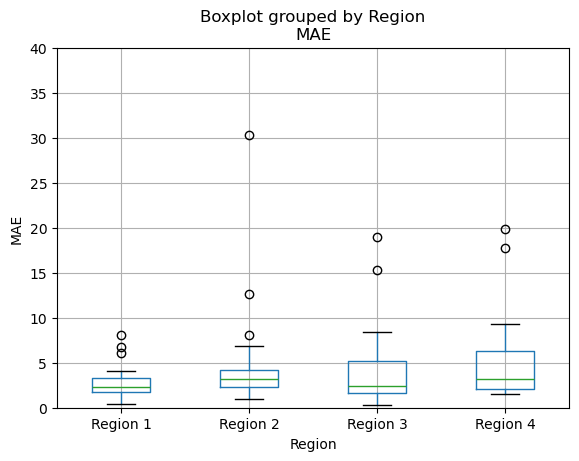

In [13]:
# Now we can test on the testing_df seperated in region

model_scores = []

for unit, unit_df in testing_df.groupby("Unit"):

    pred = model.predict(unit_df[feature_columns])
    model_scores.append( {"Unit": unit, "Region": unit_df["Region"].iloc[0], "MAE": mae(unit_df["average_power"], pred)} )
    testing_df.loc[unit_df.index, "xgb_pred"] = pred

model_scores = pd.DataFrame(model_scores)

plt.figure(figsize=(5,5))
model_scores.boxplot(column=["MAE"], by="Region")
plt.ylabel("MAE")
plt.ylim(0, 40)
plt.show()

In [25]:
model_scores.sort_values("MAE").tail()

,Unit,Region,MAE
65,Prairie Island 2,Region 3,15.348424
68,River Bend 1,Region 4,17.704292
64,Prairie Island 1,Region 3,18.951479
88,Waterford 3,Region 4,19.873303
76,Sequoyah 2,Region 2,30.332878


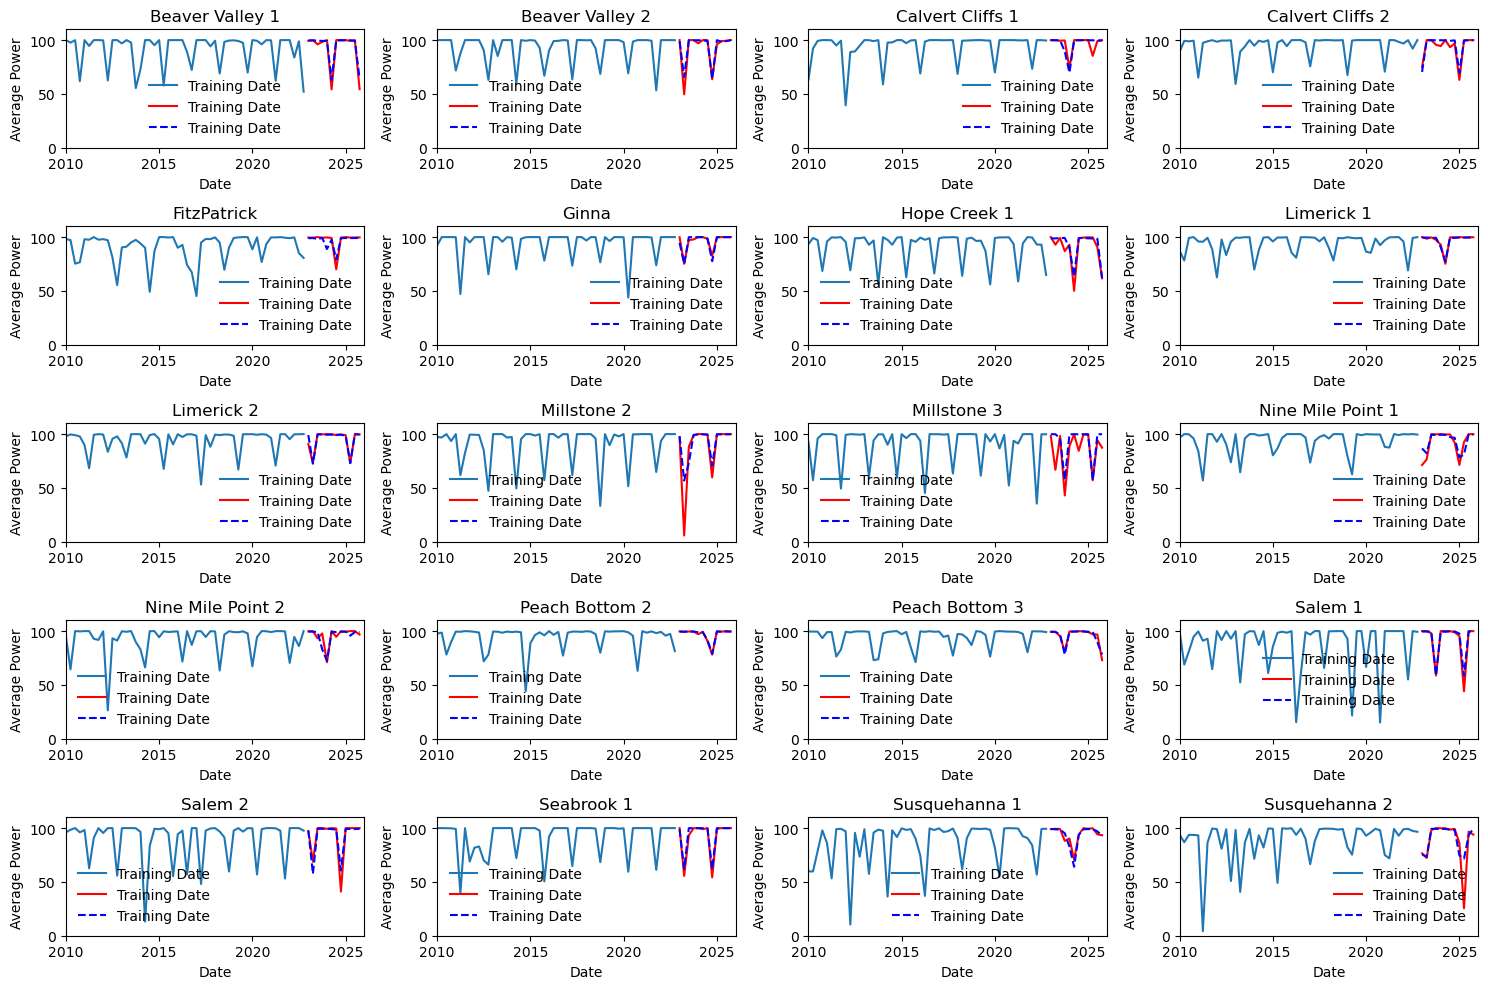

In [27]:
import math 
import matplotlib.dates as mdates

region="Region 1"
regional_df = testing_df[ testing_df["Region"] == region ]
reactors = regional_df["Unit"].unique()

n_rows = 5
n_columns = math.ceil(len(reactors)/n_rows)

fig, axes = plt.subplots(n_rows, n_columns, figsize=(15,10))
axes = axes.flatten()

for i in range(len(reactors)):

    mask = training_df["Unit"] == reactors[i]

    axes[i].plot(training_df[mask]["quarter_start"], training_df[mask]["average_power"], label='Training Date')

    axes[i].plot(regional_df[regional_df["Unit"] == reactors[i]]["quarter_start"], regional_df[regional_df["Unit"] == reactors[i]]["average_power"], label='Training Date', color='red')

    axes[i].plot(regional_df[regional_df["Unit"] == reactors[i]]["quarter_start"], regional_df[regional_df["Unit"] == reactors[i]]["xgb_pred"], "--", label='Training Date', color='blue')

    axes[i].set_xlabel("Date")
    axes[i].set_ylabel("Average Power")
    axes[i].set_title(f'{reactors[i]}')
    axes[i].legend(frameon=False)
    axes[i].set_xlim(pd.Timestamp("2010-01-01"), pd.Timestamp("2026-01-01"))
    axes[i].set_ylim(0, 110)

    axes[i].xaxis.set_major_locator(mdates.YearLocator(5))

plt.tight_layout()
plt.show()

In [24]:

summary = model_scores["MAE"].describe(percentiles=[0.25, 0.5, 0.75, 0.9])
summary.round(2)

count    92.00
mean      4.31
std       4.62
min       0.34
25%       2.03
50%       2.96
75%       4.51
90%       8.02
max      30.33
Name: MAE, dtype: float64

## Conclusions

Test MAE per reactor over 2023–2025 (92 reactors, in percentage points of full power), compared with the best univariate model from `PreliminaryForecasts.ipynb`:

- **XGBoost is the most accurate model we have tried.** Compared with the seasonal average, it lowers the mean error by about 23%, the median by 25% and the 90th percentile by 28%. Both models forecast one quarter ahead using only information available at the start of the quarter, so this is a like-for-like comparison.
- **The improvement holds across most reactors, not just on average.** Every percentile up to the 90th is lower. Knowing the reactor's state going into the quarter (its power just before the quarter starts and in the previous quarter) and how far it is into its refueling cycle helps beyond repeating past cycles.
- **The hardest reactors are still hard.** The worst reactor's error barely changes (30.3 vs 32.0).
